## Filling up a section 


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from base.geometry import compute_ngon_area, return_below_fill_height, get_full_area, compute_composite_dh, fit_ellipse, compute_ngon_perimeter, centre_of_gravity, compute_ngon_wetted_perimeter

In [2]:
def plot_section_by_fill_fraction(section, fill_fractions, output_fig_path = "./temp/remplissage/test.png", show_ellipse = False) -> tuple:

    areas = []
    dh = []

    
    
    fig, axes = plt.subplots(1, 3, figsize =(10, 4)) 


    for fill_fraction in fill_fractions:
        filled_areas = return_below_fill_height(section, fill_fraction)
        area = get_full_area(section, fill_fraction)
        areas.append(area)
        
        dh.append(compute_composite_dh(section, fill_fraction))


        for filled_area in filled_areas:
            axes[0].fill(*filled_area.T, color = "dodgerblue", zorder = 10, alpha = 0.02);


    if show_ellipse == True:
        ellipse_areas = []
        ellipse_dh = []
        
        fitted_ellipse = fit_ellipse(section)
        
        for fill_fraction in fill_fractions:
            filled_areas = return_below_fill_height(fitted_ellipse[0], fill_fraction)
            ellipse_area = get_full_area(fitted_ellipse[0], fill_fraction)
            ellipse_areas.append(ellipse_area)
            
            ellipse_dh.append(compute_composite_dh(fitted_ellipse[0], fill_fraction))

        axes[0].plot(*fitted_ellipse[0].T, color = "C1", zorder = 10)
        
        ellipse_calc = ellipse_areas / get_full_area(fitted_ellipse[0], 1)
        axes[1].plot(fill_fractions, ellipse_calc, "-o", markersize = 3, color = "C1", label ="fitted ellipse")
        axes[2].plot(fill_fractions, ellipse_dh, "-o", markersize = 3, color = "C1", label = "fitted ellipse")

    
    axes[0].fill(*section.T, color = "white", edgecolor="dodgerblue")
    axes[0].set_aspect("equal")
    axes[0].set_xlabel("x [m]")
    axes[0].set_ylabel("y [m]")

    section_calc = areas / get_full_area(section, 1)
    axes[1].plot(fill_fractions, section_calc, "-o", markersize = 3, label = "original section")

    axes[1].set_xlabel("fill height fraction []")
    axes[1].set_ylabel("area fill fraction []")

    axes[2].plot(fill_fractions, dh, "-o", markersize = 3, label = "original section ")
    axes[2].set_xlabel("fill height fraction []")
    axes[2].set_ylabel("hydraulic diameter [m]")

    axes[1].legend()
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(output_fig_path)
    plt.show();
    return areas, dh

In [28]:
def plot_section_by_fill_fraction2(section, fill_fractions, output_fig_path = "./temp/remplissage/test.png", show_circle = False) -> tuple:

    areas = []
    wp = []



    
    fig, axes = plt.subplots(1, 3, figsize =(10, 4)) 


    for fill_fraction in fill_fractions:
        filled_areas = return_below_fill_height(section, fill_fraction)
        area = get_full_area(section, fill_fraction)
        areas.append(area)
        
        thewp = 0
        if fill_fraction == 1:
            thewp= compute_ngon_perimeter(section)
        else:
            for filled_area in filled_areas:
                thewp+= compute_ngon_wetted_perimeter(filled_area)
        wp.append(thewp)

        for filled_area in filled_areas:
            axes[0].fill(*filled_area.T, color = "dodgerblue", zorder = 10, alpha = 0.02);


    if show_circle == True:
        cog = centre_of_gravity(section)
        circle_dh = 4* compute_ngon_area(section) / compute_ngon_perimeter(section)
        thetai = np.linspace(-np.pi, np.pi)

        dh_circle = np.vstack([cog[0]+circle_dh/2* np.cos(thetai), cog[1]+circle_dh/2* np.sin(thetai)]).T 
        dh_circle_areas = []
        wp_circle_dh = []

        for fill_fraction in fill_fractions:
            filled_areas = return_below_fill_height(dh_circle, fill_fraction)
            dh_circle_area = get_full_area(dh_circle, fill_fraction)
            dh_circle_areas.append(dh_circle_area)
            
            if len(filled_areas) == 0:
                thewp = 0

            elif fill_fraction ==  1:
                thewp = compute_ngon_perimeter(filled_areas[0])
            else: 
                thewp = compute_ngon_wetted_perimeter(filled_areas[0])
            
            wp_circle_dh.append(thewp)

        axes[0].plot(*dh_circle.T, color = "C1", zorder = 100)
        
        axes[1].plot(fill_fractions, dh_circle_areas, "-o", markersize = 3, color = "C1", label ="Dh Circle")
        axes[2].plot(fill_fractions, wp_circle_dh, "-o", markersize = 3, color = "C1", label = "Dh circle")

    
    axes[0].fill(*section.T, color = "white", edgecolor="dodgerblue")
    axes[0].set_aspect("equal")
    axes[0].set_xlabel("x [m]")
    axes[0].set_ylabel("y [m]")

    axes[1].plot(fill_fractions, areas, "-o", markersize = 3, label = "original section")

    axes[1].set_xlabel("fill height fraction []")
    axes[1].set_ylabel("area [m^2]")

    axes[2].plot(fill_fractions, wp, "-o", markersize = 3, label = "original section ")
    axes[2].set_xlabel("fill height fraction []")
    axes[2].set_ylabel("wetted perimeter [m]")

    axes[1].legend()
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(output_fig_path)
    plt.show();
    return areas, wp

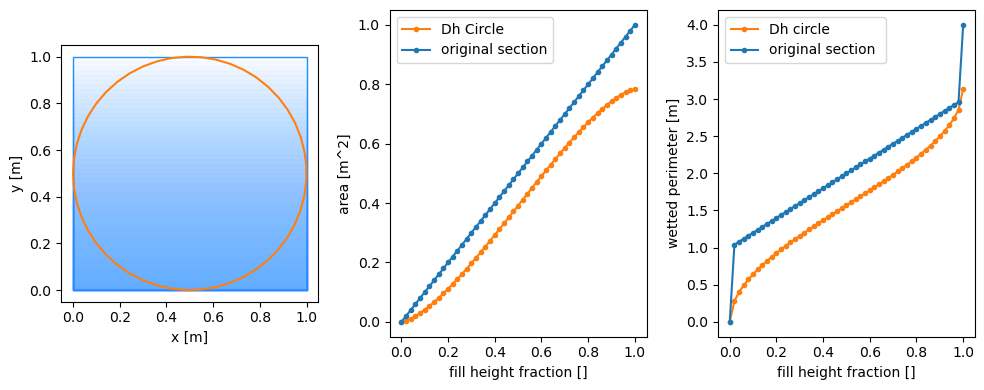

In [29]:
square = np.array([[0,0], [1, 0.],[1,1.],[0,1]])
fill_fractions = np.arange(0,1.02, 0.02)

_ = plot_section_by_fill_fraction2(square, fill_fractions,  "./temp/remplissage/test_Carre_plein.png", show_circle=True)

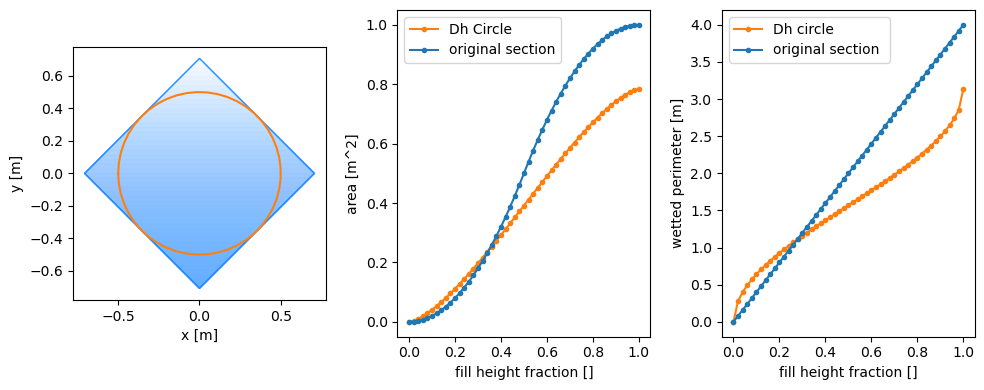

In [30]:
square2 = np.array([[0,-1/np.sqrt(2)], [1/np.sqrt(2), 0.],[0,1/np.sqrt(2)],[-1/np.sqrt(2),0]])
_ = plot_section_by_fill_fraction2(square2, fill_fractions, "./temp/remplissage/test_losange_plein.png", show_circle=True)

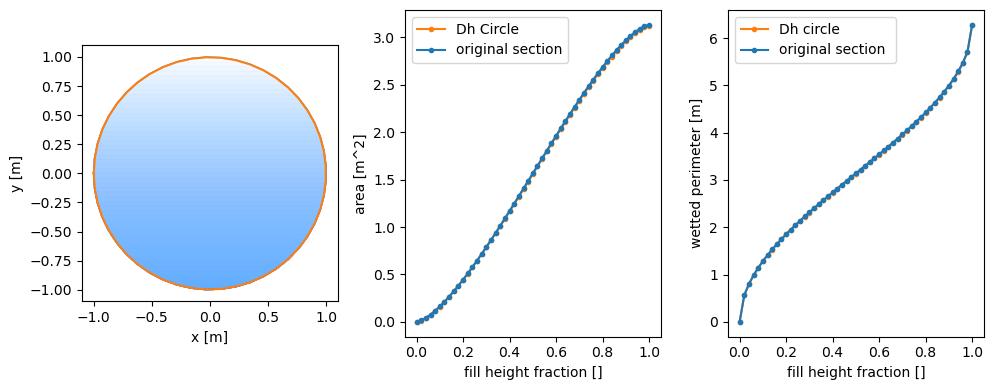

In [31]:
section_circ = np.array([np.cos(np.linspace(-np.pi, np.pi)), np.sin(np.linspace(-np.pi, np.pi))]).T
_ = plot_section_by_fill_fraction2(section_circ, fill_fractions,  "./temp/remplissage/test_cercle_plein.png", show_circle=True)

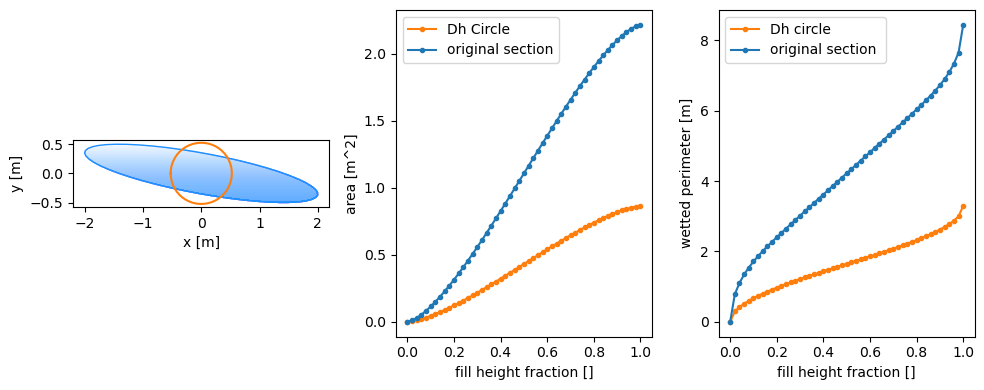

In [32]:
section_ellipse = np.array([2*np.cos(np.pi / 4 + np.linspace(-np.pi, np.pi)), 1/2*np.sin(np.linspace(-np.pi, np.pi))]).T
_ = plot_section_by_fill_fraction2(section_ellipse, fill_fractions, show_circle=True)

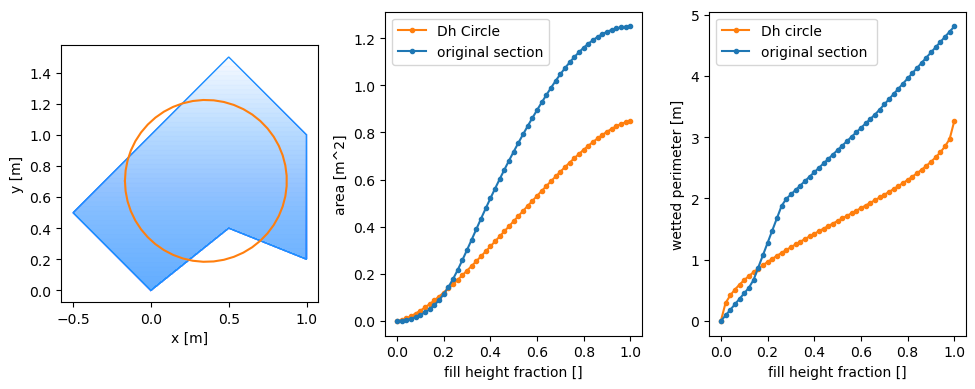

In [33]:
section = np.array([[0,0], [0.5, 0.4],[1,0.2],[1,1],[0.5,1.5],[0, 1],[-0.5, 0.5]])

_ = plot_section_by_fill_fraction2(section, fill_fractions, show_circle=True)

In [34]:
# F:\ScanLeica\from_pointcloud_to_mesh\real_data\02_GrotteDeLaCascadeDeMotiers\process\sections_as_polylines
motiers_section1 = np.loadtxt("F:ScanLeica/from_pointcloud_to_mesh/real_data/02_GrotteDeLaCascadeDeMotiers/process/sections_as_polylines/LaCave_1_reordered_2d_011.txt")

In [35]:
# F:\ScanLeica\from_pointcloud_to_mesh\real_data\02_GrotteDeLaCascadeDeMotiers\process\sections_as_polylines
motiers_section2 = np.loadtxt("F:ScanLeica/from_pointcloud_to_mesh/real_data/02_GrotteDeLaCascadeDeMotiers/process/sections_as_polylines/LaCave_1_reordered_2d_080.txt")

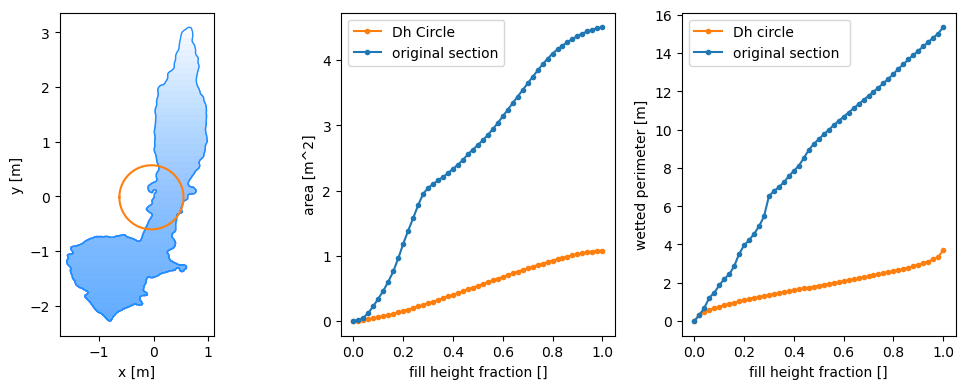

In [36]:

_ = plot_section_by_fill_fraction2(motiers_section1, fill_fractions, "./temp/remplissage/Motiers_test1.png", show_circle=True)

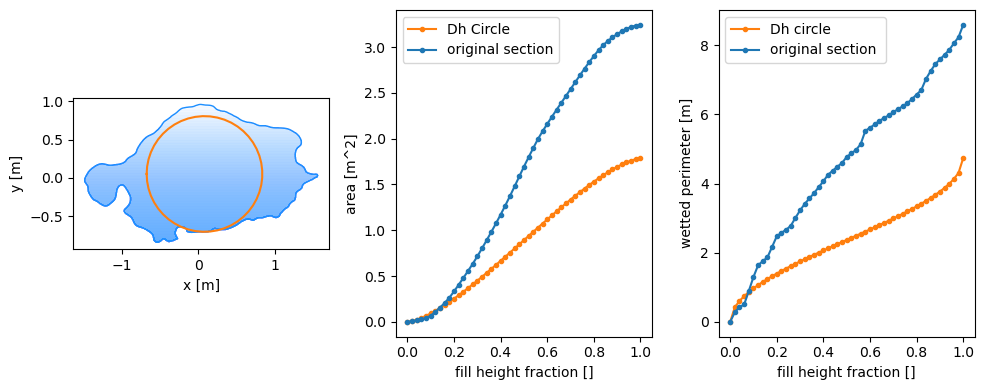

In [37]:

_ = plot_section_by_fill_fraction2(motiers_section2, fill_fractions, "./temp/remplissage/Motiers_test2.png", show_circle=True)